<a href="https://colab.research.google.com/github/SKS-Syndicate-A26-CS259/Gen-Ai/blob/main/03_RAG_VectorDB_(ChromaDB)_%26_Dual_LLM_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **03-RAG VectorDB (ChromaDB) & Dual-LLM Evaluation (Google Colab)**
## **Proyek:** Asah 2026 Capstone — Tim A26-CS259 (SKS Syndicate)
## **PIC:** Mukhamad Fariz Mubarok (`AE009B6Y1293`)
**Mitra UMKM:** UMKM Tujuan Semata (Depok, Jawa Barat)

# **Instalasi Library di Google Colab**

In [2]:
!pip install -q pandas chromadb sentence-transformers google-genai requests

# **1. Setup Path Colab, API Key, & Load 2 Dataset**

In [3]:
import os
import time
import shutil
import requests
import pandas as pd
import chromadb
from chromadb.utils import embedding_functions
from getpass import getpass
from google import genai

In [4]:
try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    GEMINI_API_KEY = os.getenv("GEMINI_API_KEY") or getpass("Masukkan GEMINI_API_KEY: ")

gemini_client = genai.Client(api_key=GEMINI_API_KEY) if GEMINI_API_KEY else None

In [6]:
MENU_PATH = "/content/katalog_menu_tujuan_semata.csv"
TESTSET_PATH = "/content/rag_golden_testset_50.csv"
CHROMA_DIR = "/content/vectorstore/chroma_menu_db"
REPORT_DIR = "/content/reports"
os.makedirs(CHROMA_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

df_menu = pd.read_csv(MENU_PATH)
df_test = pd.read_csv(TESTSET_PATH)

print(f"Status API Key     : {'Siap' if gemini_client else 'Kosong'}")
print(f"Total menu katalog : {len(df_menu)} baris | Kolom: {df_menu.columns.tolist()}")
print(f"Total skenario uji : {len(df_test)} baris ({df_test['kategori_uji'].value_counts().to_dict()})")
df_menu.head(5)

Status API Key     : Siap
Total menu katalog : 120 baris | Kolom: ['Kode_Menu', 'Nama_Menu', 'Kategori_Menu', 'Sub_Kategori', 'Harga_Jual', 'Varian_Harga_Teks', 'Komposisi_Bahan', 'Karakter_Rasa', 'Badge_Menu_Baru', 'Indikasi_Terlaris', 'Mengandung_Esens_Rum', 'Ramah_Anak', 'Segmen_Pelanggan', 'Catatan_Khusus_Owner']
Total skenario uji : 50 baris ({'relevan': 35, 'out_of_context': 15})


,Kode_Menu,Nama_Menu,Kategori_Menu,Sub_Kategori,Harga_Jual,Varian_Harga_Teks,Komposisi_Bahan,Karakter_Rasa,Badge_Menu_Baru,Indikasi_Terlaris,Mengandung_Esens_Rum,Ramah_Anak,Segmen_Pelanggan,Catatan_Khusus_Owner
0,MN-001,Coffee Latte,Coffee,Kopi Susu,12000,Rp12.000 / Rp16.000,"Espresso, susu segar, gula cair","Kopi, Creamy, Manis Seimbang",False,False,False,False,Mahasiswa,Mengandung Kafein
1,MN-002,Coffee Milo,Coffee,Kopi Susu,14000,Rp14.000 / Rp18.000,"Espresso, bubuk cokelat malt Milo, susu segar","Kopi, Creamy, Manis Seimbang",False,False,False,False,Mahasiswa,Mengandung Kafein
2,MN-003,Blue Mint Latte,Coffee,Kopi Susu,16000,Rp16.000 / Rp20.000,"Espresso, sirup blue curacao & peppermint ding...","Kopi, Creamy, Manis Segar Mint",False,False,False,False,Mahasiswa,Mengandung Kafein
3,MN-004,Tujuan Signature,Coffee,Kopi Susu,14000,Rp14.000 / Rp18.000,Double shot espresso racikan khusus Tujuan Sem...,"Kopi, Creamy, Manis Seimbang",False,True,False,False,Mahasiswa,Mengandung Kafein
4,MN-005,Vanilla Latte,Coffee,Kopi Susu,14000,Rp14.000 / Rp18.000,"Espresso, sirup vanilla, susu full cream","Kopi, Creamy, Manis Seimbang",False,False,False,False,Mahasiswa,Mengandung Kafein


# **2. Format Dokumen RAG dari katalog_menu_tujuan_semata.csv**

In [7]:
def to_bool(val) -> bool:
    return str(val).strip().lower() in ["true", "1", "ya"]

documents, metadatas, ids = [], [], []

for _, row in df_menu.iterrows():
    is_new = to_bool(row["Badge_Menu_Baru"])
    is_best = to_bool(row["Indikasi_Terlaris"])
    has_rum = to_bool(row["Mengandung_Esens_Rum"])
    kid_friendly = to_bool(row["Ramah_Anak"])
    catatan = str(row["Catatan_Khusus_Owner"]) if pd.notna(row["Catatan_Khusus_Owner"]) else "-"

    doc_text = (
        f"Menu: {row['Nama_Menu']} (Kode: {row['Kode_Menu']}). "
        f"Kategori: {row['Kategori_Menu']} - Sub Kategori: {row['Sub_Kategori']}. "
        f"Harga Mulai: Rp{int(row['Harga_Jual']):,} (Varian Harga: {row['Varian_Harga_Teks']}). "
        f"Komposisi Bahan: {row['Komposisi_Bahan']}. "
        f"Karakter Rasa: {row['Karakter_Rasa']}. "
        f"Status Menu Baru: {'Ya' if is_new else 'Tidak'}. "
        f"Menu Terlaris (Best Seller): {'Ya' if is_best else 'Tidak'}. "
        f"Mengandung Esens Rum Non-Alkohol: {'Ya' if has_rum else 'Tidak'}. "
        f"Ramah Anak: {'Ya (tanpa kafein & tidak pedas)' if kid_friendly else 'Tidak'}. "
        f"Segmen Pelanggan: {row['Segmen_Pelanggan']}. "
        f"Catatan Khusus Owner: {catatan}."
    )
    documents.append(doc_text)
    metadatas.append({
        "kode_menu": str(row["Kode_Menu"]),
        "nama_menu": str(row["Nama_Menu"]),
        "kategori_menu": str(row["Kategori_Menu"]),
        "harga_jual": int(row["Harga_Jual"]),
        "menu_terlaris": is_best,
        "menu_baru": is_new,
        "ramah_anak": kid_friendly,
        "mengandung_esens_rum": has_rum,
    })
    ids.append(str(row["Kode_Menu"]))

store_docs = [
    (
        "INFO-WARUNG-01",
        "Profil UMKM Tujuan Semata: Kedai F&B yang berlokasi di Depok, Jawa Barat dan telah beroperasi sejak 2022 (dikelola langsung oleh Ibu Shinta). Menyediakan sekitar 120 varian minuman kopi, non-kopi, matcha, cokelat, teh, soda refresher, camilan gurih, pasta, dan dessert.",
        {"kode_menu": "INFO-01", "nama_menu": "Profil Warung", "kategori_menu": "Info Operasional", "harga_jual": 0, "menu_terlaris": False, "menu_baru": False, "ramah_anak": True, "mengandung_esens_rum": False},
    ),
    (
        "INFO-WARUNG-02",
        "Alur Pemesanan & Pembayaran UMKM Tujuan Semata: Pelanggan dapat melihat katalog, memilih menu, dan menunjukkan Ringkasan Pilihan Menu di web ke kasir untuk mempercepat pencatatan dan mencegah salah dengar atau double order. Website belum mendukung pembayaran online (QRIS/VA); seluruh pembayaran dilakukan langsung di kasir.",
        {"kode_menu": "INFO-02", "nama_menu": "Alur Pesan & Bayar", "kategori_menu": "Info Operasional", "harga_jual": 0, "menu_terlaris": False, "menu_baru": False, "ramah_anak": True, "mengandung_esens_rum": False},
    ),
]

for doc_id, text, meta in store_docs:
    ids.append(doc_id)
    documents.append(text)
    metadatas.append(meta)

print(f"Total dokumen siap indeks ke ChromaDB: {len(documents)}")
print("Contoh dokumen pertama:\n", documents[0])

Total dokumen siap indeks ke ChromaDB: 122
Contoh dokumen pertama:
 Menu: Coffee Latte (Kode: MN-001). Kategori: Coffee - Sub Kategori: Kopi Susu. Harga Mulai: Rp12,000 (Varian Harga: Rp12.000 / Rp16.000). Komposisi Bahan: Espresso, susu segar, gula cair. Karakter Rasa: Kopi, Creamy, Manis Seimbang. Status Menu Baru: Tidak. Menu Terlaris (Best Seller): Tidak. Mengandung Esens Rum Non-Alkohol: Tidak. Ramah Anak: Tidak. Segmen Pelanggan: Mahasiswa. Catatan Khusus Owner: Mengandung Kafein.


# **3. Indexing ke ChromaDB Persisten & Uji Retrieval**

In [8]:
if os.path.exists(CHROMA_DIR):
    shutil.rmtree(CHROMA_DIR)
os.makedirs(CHROMA_DIR, exist_ok=True)

embed_fn = embedding_functions.SentenceTransformerEmbeddingFunction(
    model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)
collection = chroma_client.get_or_create_collection(
    name="tujuan_semata_menu",
    embedding_function=embed_fn,
    metadata={"hnsw:space": "cosine"},
)

collection.add(ids=ids, documents=documents, metadatas=metadatas)
print(f"Berhasil mengindeks {collection.count()} dokumen ke {CHROMA_DIR}")

def retrieve_menu_context(query: str, top_k: int = 4) -> list[str]:
    res = collection.query(query_texts=[query], n_results=top_k)
    return res["documents"][0] if res and res["documents"] else []

for sample_q in ["kopi esens rum halal tidak", "minuman ramah anak tanpa kopi"]:
    print(f"\n[Query]: {sample_q}")
    for i, doc in enumerate(retrieve_menu_context(sample_q, top_k=2), 1):
        print(f"  {i}. {doc[:150]}...")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Berhasil mengindeks 122 dokumen ke /content/vectorstore/chroma_menu_db

[Query]: kopi esens rum halal tidak
  1. Menu: Matcha Milk (Kode: MN-033). Kategori: Creamy & Non-Coffee - Sub Kategori: Minuman Creamy / Non-Kopi. Harga Mulai: Rp5,000 (Varian Harga: Rp5.000...
  2. Menu: Coklat Milk (Kode: MN-038). Kategori: Creamy & Non-Coffee - Sub Kategori: Minuman Creamy / Non-Kopi. Harga Mulai: Rp5,000 (Varian Harga: Rp5.000...

[Query]: minuman ramah anak tanpa kopi
  1. Menu: Coffee Latte (Kode: MN-001). Kategori: Coffee - Sub Kategori: Kopi Susu. Harga Mulai: Rp12,000 (Varian Harga: Rp12.000 / Rp16.000). Komposisi Ba...
  2. Menu: Coklat Milk (Kode: MN-038). Kategori: Creamy & Non-Coffee - Sub Kategori: Minuman Creamy / Non-Kopi. Harga Mulai: Rp5,000 (Varian Harga: Rp5.000...


# **4. Pipeline Dual-LLM (Primary Gemini API vs Secondary Local Qwen / Fallback)**

In [25]:
SYSTEM_PROMPT = """Kamu adalah Asisten Menu resmi UMKM Tujuan Semata (Depok, Jawa Barat).
ATURAN KETAT:
1. Jawab HANYA berdasarkan KONTEKS MENU yang diberikan. Jangan pernah mengarang menu, harga, atau promo di luar konteks.
2. Jika ditanya tentang data internal/rahasia (seperti modal HPP, omzet, atau nomor HP/data pribadi member) atau topik di luar UMKM Tujuan Semata (politik, coding, saham, merek lain, wisata, film, dll.), TOLAK DENGAN SOPAN dan arahkan kembali ke pertanyaan seputar menu atau layanan UMKM Tujuan Semata.
3. Jika ada pertanyaan mengenai kopi dengan rum, jelaskan dengan tegas sesuai catatan owner bahwa yang digunakan adalah esens rum non-alkohol.
4. Gunakan bahasa Indonesia yang ramah, ringkas, dan jelas."""

OOC_SENSITIVE_PATTERNS = [
    "hpp", "modal", "omzet", "untung", "profit", "nomor hp", "data member",
    "presiden", "pemilu", "python", "scraping", "coding", "saham", "starbucks",
    "integral", "bola", "obat", "jepang", "meretas", "hotel", "ojek online", "avengers"
]

def is_obviously_blocked(query: str) -> bool:
    q_low = query.lower()
    return any(p in q_low for p in OOC_SENSITIVE_PATTERNS)

POLITE_REFUSAL = (
    "Maaf, saya hanya dapat membantu menjawab pertanyaan seputar menu, harga, "
    "komposisi, dan layanan UMKM Tujuan Semata."
)

def ask_gemini_rag(query: str, top_k: int = 4) -> tuple[str, float, list[str]]:
    start = time.perf_counter()
    if is_obviously_blocked(query):
        return POLITE_REFUSAL, round(time.perf_counter() - start, 3), []

    contexts = retrieve_menu_context(query, top_k=top_k)
    context_block = "\n".join(f"- {c}" for c in contexts)
    prompt = f"{SYSTEM_PROMPT}\n\nKONTEKS MENU:\n{context_block}\n\nPERTANYAAN PELANGGAN: {query}\nJAWABAN:"

    if gemini_client is None:
        return "[GEMINI_API_KEY belum diset]", round(time.perf_counter() - start, 3), contexts

    try:
        response = gemini_client.models.generate_content(
            model="gemini-3.1-flash-lite",
            contents=prompt,
        )
        text = response.text.strip()
    except Exception as e:
        text = f"[Error Gemini API]: {e}"

    elapsed = round(time.perf_counter() - start, 3)
    return text, elapsed, contexts

def ask_local_qwen_or_fallback(query: str, top_k: int = 4, ollama_url: str = "http://localhost:11434/api/generate") -> tuple[str, float]:
    start = time.perf_counter()
    if is_obviously_blocked(query):
        return POLITE_REFUSAL, round(time.perf_counter() - start, 3)

    contexts = retrieve_menu_context(query, top_k=top_k)
    context_block = "\n".join(f"- {c}" for c in contexts)
    prompt = f"{SYSTEM_PROMPT}\n\nKONTEKS MENU:\n{context_block}\n\nPERTANYAAN PELANGGAN: {query}\nJAWABAN:"

    try:
        r = requests.post(
            ollama_url,
            json={"model": "qwen2.5:3b", "prompt": prompt, "stream": False},
            timeout=5,
        )
        if r.status_code == 200:
            return r.json().get("response", "").strip(), round(time.perf_counter() - start, 3)
    except Exception:
        pass

    summary = "Berdasarkan katalog UMKM Tujuan Semata, berikut informasi yang paling relevan:\n" + "\n".join(contexts[:2])
    return summary, round(time.perf_counter() - start, 3)

# **5. Evaluasi 50 Skenario Golden Test Set (35 Relevan + 15 Out-of-Context)**

In [26]:
def check_pass(answer: str, expected_keywords: str, kategori_uji: str) -> bool:
    ans_low = answer.lower()
    if "[gemini_api_key" in ans_low:
        return False
    kws = [k.strip().lower() for k in str(expected_keywords).split("|") if k.strip()]
    matched = any(k in ans_low for k in kws)
    if kategori_uji == "out_of_context":
        return ("maaf" in ans_low or "tidak dapat" in ans_low) and matched
    return matched

eval_records = []
for idx, row in df_test.iterrows():
    q = row["pertanyaan"]
    kat = row["kategori_uji"]
    exp_kw = row["expected_keywords"]

    gem_ans, gem_lat, ctxs = ask_gemini_rag(q)
    fb_ans, fb_lat = ask_local_qwen_or_fallback(q)

    time.sleep(1.5)

    eval_records.append({
        "id_uji": row["id_uji"],
        "kategori_uji": kat,
        "pertanyaan": q,
        "expected_keywords": exp_kw,
        "gemini_answer": gem_ans,
        "gemini_latency_s": gem_lat,
        "gemini_pass": check_pass(gem_ans, exp_kw, kat),
        "fallback_answer": fb_ans,
        "fallback_latency_s": fb_lat,
        "fallback_pass": check_pass(fb_ans, exp_kw, kat),
        "top1_context": ctxs[0][:120] if ctxs else "",
    })

df_eval = pd.DataFrame(eval_records)
eval_csv_path = os.path.join(REPORT_DIR, "rag_dual_llm_eval_50.csv")
df_eval.to_csv(eval_csv_path, index=False)
print(f"Log evaluasi 50 skenario disimpan ke: {eval_csv_path}")

summary_rows = []
for model_name, pass_col, lat_col in [
    ("Primary (Gemini API + ChromaDB)", "gemini_pass", "gemini_latency_s"),
    ("Secondary (Local Qwen / Fallback)", "fallback_pass", "fallback_latency_s"),
]:
    rel_df = df_eval[df_eval["kategori_uji"] == "relevan"]
    ooc_df = df_eval[df_eval["kategori_uji"] == "out_of_context"]
    summary_rows.append({
        "Model": model_name,
        "Akurasi_Relevan_Pct": round(rel_df[pass_col].mean() * 100, 1),
        "Lulus_Relevan": f"{int(rel_df[pass_col].sum())}/{len(rel_df)}",
        "OOC_Refusal_Pct": round(ooc_df[pass_col].mean() * 100, 1),
        "Lulus_OOC": f"{int(ooc_df[pass_col].sum())}/{len(ooc_df)}",
        "Avg_Latency_s": round(df_eval[lat_col].mean(), 3),
    })

Log evaluasi 50 skenario disimpan ke: /content/reports/rag_dual_llm_eval_50.csv


In [27]:
ans, lat, _ = ask_gemini_rag("Apa saja menu kopi signature yang ada di Tujuan Semata?")
print("Latensi:", lat)
print("Output :", ans)

Latensi: 1.269
Output : Menu kopi signature yang tersedia di Tujuan Semata adalah **Tujuan Signature (MN-004)**.

Berikut detail menunya:
*   **Kategori:** Coffee - Kopi Susu
*   **Harga:** Rp14.000 / Rp18.000
*   **Komposisi:** Double shot espresso racikan khusus Tujuan Semata, gula aren/krim spesial, dan susu full cream.
*   **Karakter Rasa:** Kopi, Creamy, dan Manis Seimbang.
*   **Status:** Merupakan salah satu menu *Best Seller* kami.

Menu ini mengandung kafein dan ditujukan bagi segmen mahasiswa. Apakah ada hal lain yang ingin Anda tanyakan mengenai menu kami?


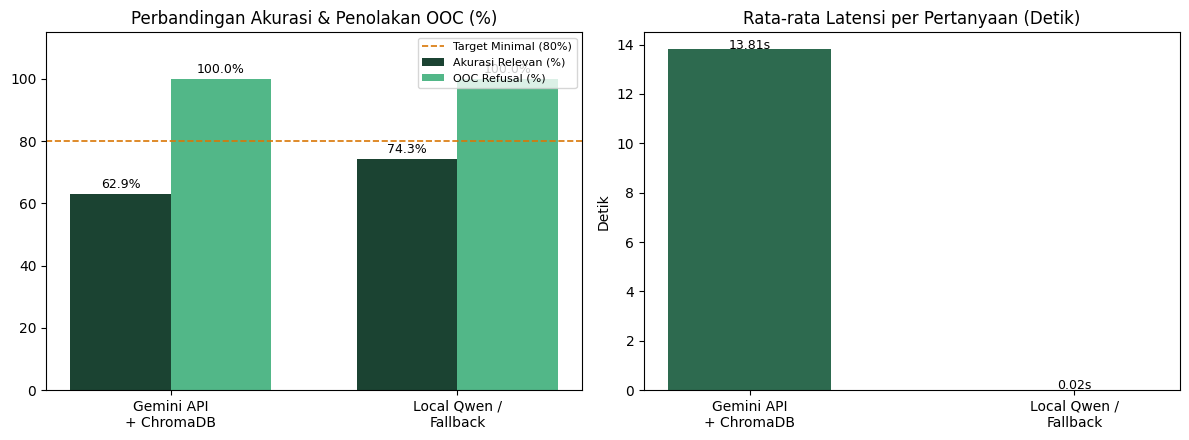

Grafik disimpan ke: /content/reports/rag_dual_llm_comparison.png


In [28]:
import matplotlib.pyplot as plt
import numpy as np

df_sum = pd.DataFrame(summary_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

x = np.arange(len(df_sum))
width = 0.35
b1 = axes[0].bar(x - width/2, df_sum["Akurasi_Relevan_Pct"], width, label="Akurasi Relevan (%)", color="#1B4332")
b2 = axes[0].bar(x + width/2, df_sum["OOC_Refusal_Pct"], width, label="OOC Refusal (%)", color="#52B788")
axes[0].axhline(80, color="#D97706", linestyle="--", linewidth=1.2, label="Target Minimal (80%)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Gemini API\n+ ChromaDB", "Local Qwen /\nFallback"])
axes[0].set_ylim(0, 115)
axes[0].set_title("Perbandingan Akurasi & Penolakan OOC (%)")
axes[0].legend(fontsize=8)
for bar in list(b1) + list(b2):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{bar.get_height():.1f}%", ha="center", fontsize=9)

b3 = axes[1].bar(df_sum["Model"], df_sum["Avg_Latency_s"], color=["#2D6A4F", "#74C69D"], width=0.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Gemini API\n+ ChromaDB", "Local Qwen /\nFallback"])
axes[1].set_title("Rata-rata Latensi per Pertanyaan (Detik)")
axes[1].set_ylabel("Detik")
for bar in b3:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f"{bar.get_height():.2f}s", ha="center", fontsize=9)

plt.tight_layout()
fig_path = os.path.join(REPORT_DIR, "rag_dual_llm_comparison.png")
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Grafik disimpan ke: {fig_path}")

In [29]:
for m in gemini_client.models.list():
    if "flash" in m.name.lower():
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


In [30]:
from google.colab import files

!zip -r -q /content/chroma_menu_db.zip /content/vectorstore/chroma_menu_db
files.download("/content/chroma_menu_db.zip")
files.download("/content/reports/rag_dual_llm_eval_50.csv")
files.download("/content/reports/rag_dual_llm_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>